# Lecture 4 — Class Exercise
## Scatter & Bubble Charts: Gapminder

> **Push to:** `week04/lecture04_exercise.ipynb`

**Rules:**
1. Colour used **sparingly** — one categorical variable, no rainbow
2. If showing all continents, either use accessible palette OR grey all + highlight one
3. `size_max` set when using bubble size
4. Log scale for GDP per capita
5. Insight title

---


In [1]:
import pandas as pd
import plotly.express as px


# Dataset: Gapminder — GDP, Life Expectancy, Population by Country
# Source: Gapminder Foundation (gapminder.org)

df = px.data.gapminder()
print(f"Loaded: {len(df)} rows")
print(df.head())

Loaded: 1704 rows
       country continent  year  lifeExp       pop   gdpPercap iso_alpha  \
0  Afghanistan      Asia  1952   28.801   8425333  779.445314       AFG   
1  Afghanistan      Asia  1957   30.332   9240934  820.853030       AFG   
2  Afghanistan      Asia  1962   31.997  10267083  853.100710       AFG   
3  Afghanistan      Asia  1967   34.020  11537966  836.197138       AFG   
4  Afghanistan      Asia  1972   36.088  13079460  739.981106       AFG   

   iso_num  
0        4  
1        4  
2        4  
3        4  
4        4  


In [2]:
# explore

print(df.info())
print("Years:", sorted(df['year'].unique()))
print("Continents:", df['continent'].unique())
print(df.describe().round(1))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1704 non-null   object 
 1   continent  1704 non-null   object 
 2   year       1704 non-null   int64  
 3   lifeExp    1704 non-null   float64
 4   pop        1704 non-null   int64  
 5   gdpPercap  1704 non-null   float64
 6   iso_alpha  1704 non-null   object 
 7   iso_num    1704 non-null   int64  
dtypes: float64(2), int64(3), object(3)
memory usage: 106.6+ KB
None
Years: [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)]
Continents: ['Asia' 'Europe' 'Africa' 'Americas' 'Oceania']
         year  lifeExp           pop  gdpPercap  iso_num
count  1704.0   1704.0  1.704000e+03     1704.0   1704.0
mean   1979.5     59.5  2.960121e+07     7215.3    

## Task 1 — Scatter: life expectancy change over time

**What to build:** A scatter showing **GDP per capita vs life expectancy** for **two years** (2002 and 2007) to show how both moved — use **colour for year** (just 2 colours), **one continent only**.

Choose any continent except Africa (that was the example). Highlight the change direction.

> 💡 Filter: `df.loc[df['continent'] == 'YOUR_CHOICE']` then filter years


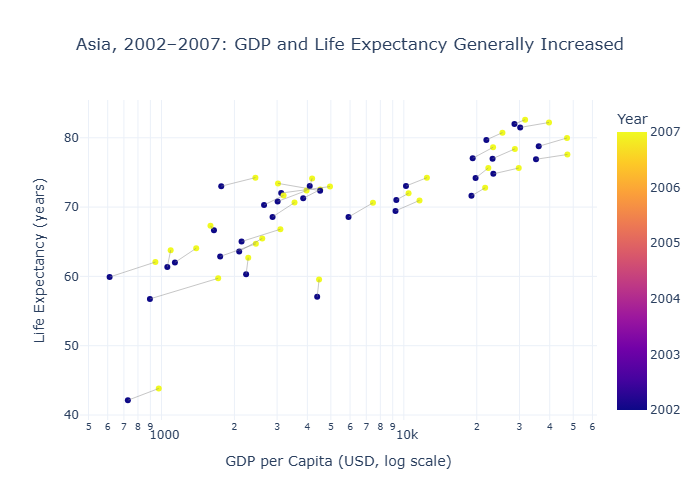

In [4]:

# Task 1: GDP per capita vs life expectancy (Asia, 2002 and 2007)

import plotly.express as px
import plotly.graph_objects as go

# Filter to Asia and the two required years
years = [2002, 2007]

asia = df.loc[
    (df["continent"] == "Asia") &
    (df["year"].isin(years))
].copy()

# Create the scatter plot, using only two colours for the years
fig = px.scatter(
    asia,
    x="gdpPercap",
    y="lifeExp",
    color="year",
    color_discrete_map={
        2002: "#2878B5",
        2007: "#F28E2B"
    },
    hover_name="country",
    hover_data={
        "gdpPercap": ":,.0f",
        "lifeExp": ":.1f",
        "year": True
    },
    title="Asia, 2002–2007: GDP and Life Expectancy Generally Increased",
    labels={
        "gdpPercap": "GDP per Capita (USD, log scale)",
        "lifeExp": "Life Expectancy (years)",
        "year": "Year"
    }
)

# Add connecting lines to show each country's direction of change
for country in asia["country"].unique():
    country_data = asia[asia["country"] == country].sort_values("year")

    if len(country_data) == 2:
        fig.add_trace(
            go.Scatter(
                x=country_data["gdpPercap"],
                y=country_data["lifeExp"],
                mode="lines",
                line=dict(color="gray", width=1),
                opacity=0.45,
                showlegend=False,
                hoverinfo="skip"
            )
        )

# Apply the logarithmic scale to GDP per capita
fig.update_xaxes(type="log")

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    legend_title_text="Year"
)

fig.show(renderer="png")

## Task 2 — Bubble chart: tell a story

**What to build:** A bubble chart (full 2007 dataset, all countries) where:
- x = GDP per capita (log scale)
- y = life expectancy
- size = population
- colour = ONE continent highlighted (your choice), all others grey
- At least one annotation explaining the highlighted group's story

> This is the grey-and-highlight technique applied to a bubble chart.


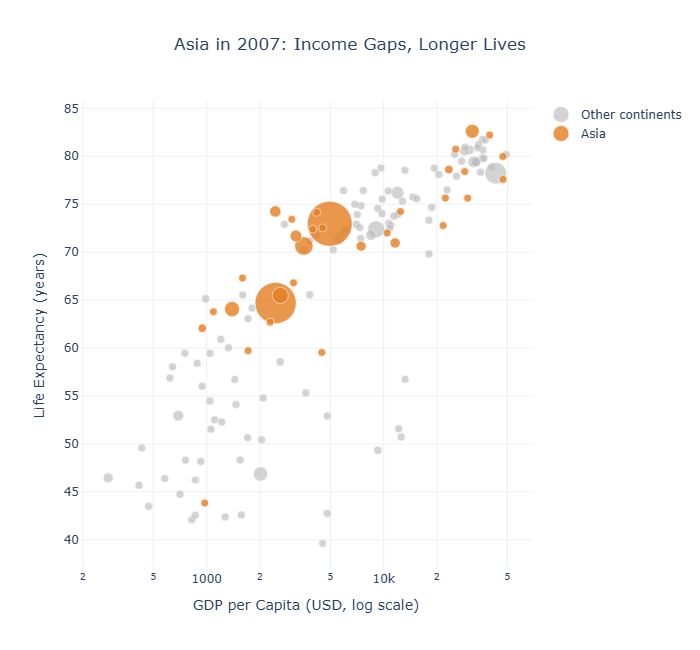

In [5]:
# Task 2
# YOUR CODE HERE

# Task 2: Bubble chart — tell a story

import plotly.graph_objects as go

# Use the full dataset for 2007
df_2007 = df[df["year"] == 2007].copy()

# Highlight Asia and show all other continents in grey
highlight_continent = "Asia"

other_continents = df_2007[
    df_2007["continent"] != highlight_continent
]

highlight = df_2007[
    df_2007["continent"] == highlight_continent
]

fig = go.Figure()

# All other continents in grey
fig.add_trace(
    go.Scatter(
        x=other_continents["gdpPercap"],
        y=other_continents["lifeExp"],
        mode="markers",
        name="Other continents",
        text=other_continents["country"],
        marker=dict(
            size=other_continents["pop"],
            sizemode="area",
            sizeref=2.0 * df_2007["pop"].max() / (45**2),
            sizemin=4,
            color="#BDBDBD",
            opacity=0.65,
            line=dict(width=0.5, color="white")
        ),
        hovertemplate=(
            "<b>%{text}</b><br>"
            "GDP per capita: $%{x:,.0f}<br>"
            "Life expectancy: %{y:.1f} years"
            "<extra>Other continents</extra>"
        )
    )
)

# Highlight Asia
fig.add_trace(
    go.Scatter(
        x=highlight["gdpPercap"],
        y=highlight["lifeExp"],
        mode="markers",
        name="Asia",
        text=highlight["country"],
        marker=dict(
            size=highlight["pop"],
            sizemode="area",
            sizeref=2.0 * df_2007["pop"].max() / (45**2),
            sizemin=4,
            color="#E67E22",
            opacity=0.8,
            line=dict(width=0.7, color="white")
        ),
        hovertemplate=(
            "<b>%{text}</b><br>"
            "GDP per capita: $%{x:,.0f}<br>"
            "Life expectancy: %{y:.1f} years"
            "<extra>Asia</extra>"
        )
    )
)

# Add an annotation explaining Asia's story
fig.add_annotation(
    x=2500,
    y=68,
    text="Asia: wide differences in income,<br>"
         "while many countries reach higher<br>"
         "life expectancy",
    showarrow=True,
    arrowhead=2,
    ax=75,
    ay=-65,
    bgcolor="white",
    bordercolor="#E67E22",
    font=dict(color="#333333", size=11)
)

# Log scale for GDP per capita
fig.update_xaxes(type="log")

fig.update_layout(
    title={
        "text": "Asia in 2007: Income Gaps, Longer Lives",
        "x": 0.5
    },
    xaxis_title="GDP per Capita (USD, log scale)",
    yaxis_title="Life Expectancy (years)",
    template="plotly_white",
    legend_title_text="",
    height=650
)

fig.show(renderer="png")